## 4.1 Persiapan Data Transaksi

In [2]:
%pip install mlxtend

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.4 MB 1.8 MB/s eta 0:00:01
   ----------------------- ---------------- 0.8/1.4 MB 2.2 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 1.7 MB/s  0:00:00
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 1.8 MB/s eta 0:00:05
   ---- ----------------------------------- 1.0/9.3 MB 2.0 MB/s eta 0:00:05
   ----- ---------------------------------- 1.3/9.3 MB 1.7 MB/s eta 0:00:05
   ------ --------------------------------- 1.6/9.3 MB 1.7 MB/s eta 0:00:05
   ------- -------------------------------- 1.8/9.3 MB 1.6 MB/s eta 0:00:05
   -------- ------------------------------- 2.1/9.3 MB 1.6 MB/s eta 0:00:05
   ---------- -----------------------------

In [5]:
import pandas as pd
import numpy as np
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
# transactions: list berisi 60 transaksi (daftar item per transaksi)

raw = pd.read_csv('transactions_arm_praktikum.csv')
# Ubah kolom Items ("Gula, Kopi, Susu") menjadi list of list
transactions = [
    [item.strip() for item in row.split(',')]
    for row in raw['Items']
]
print('Jumlah transaksi:', len(transactions))
for i, t in enumerate(transactions[:5], 1):
 print(f'T{i}: {t}')


Jumlah transaksi: 60
T1: ['Gula', 'Kopi', 'Susu']
T2: ['Gula', 'Kopi', 'Susu']
T3: ['Mentega', 'Roti', 'Susu', 'Telur']
T4: ['Mie Instan']
T5: ['Keju', 'Roti', 'Susu', 'Telur']


In [6]:
from collections import Counter
cnt = Counter()
for t in transactions:
 cnt.update(t)
for item, freq in cnt.most_common():
 print(f'{item:12s}: {freq:2d} (support = {freq/len(transactions):.3f})')

Susu        : 19 (support = 0.317)
Roti        : 18 (support = 0.300)
Mie Instan  : 18 (support = 0.300)
Mentega     : 17 (support = 0.283)
Telur       : 15 (support = 0.250)
Sabun       : 15 (support = 0.250)
Gula        : 14 (support = 0.233)
Kopi        : 13 (support = 0.217)
Shampo      : 13 (support = 0.217)
Kecap       : 12 (support = 0.200)
Keju        :  6 (support = 0.100)
Teh         :  4 (support = 0.067)


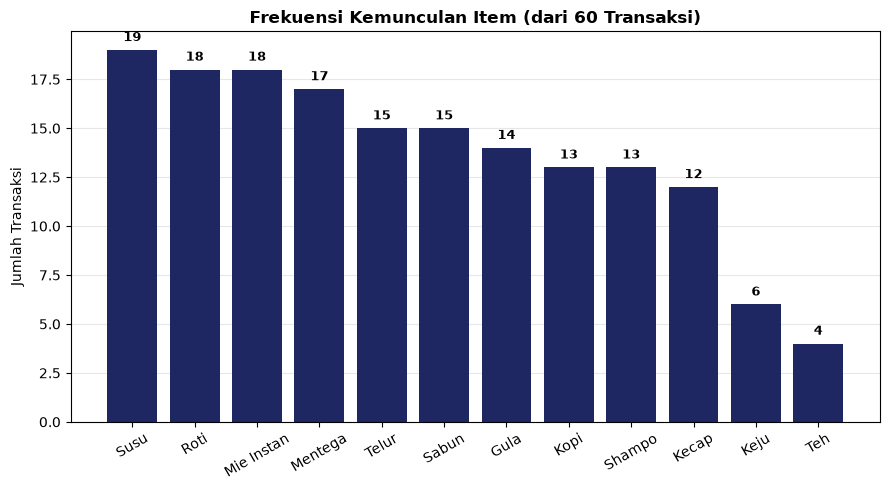

In [7]:
import matplotlib.pyplot as plt

items  = [item for item, freq in cnt.most_common()]
freqs  = [freq for item, freq in cnt.most_common()]

plt.figure(figsize=(9, 5))
bars = plt.bar(items, freqs, color='#1E2761')

# Tampilkan angka di atas tiap bar
for bar, f in zip(bars, freqs):
    plt.text(bar.get_x() + bar.get_width()/2, f + 0.3, str(f),
             ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.title('Frekuensi Kemunculan Item (dari 60 Transaksi)', fontweight='bold')
plt.ylabel('Jumlah Transaksi')
plt.xticks(rotation=30)
plt.grid(axis='y', alpha=0.3)
plt.gca().set_axisbelow(True)
plt.tight_layout()
plt.show()

## 4.2 Encoding Data Transaksi ke Format One-Hot

In [9]:
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df = pd.DataFrame(te_ary, columns=te.columns_)
print('Ukuran matriks one-hot:', df.shape)
print(df.iloc[:5, :6])


Ukuran matriks one-hot: (60, 12)
    Gula  Kecap   Keju   Kopi  Mentega  Mie Instan
0   True  False  False   True    False       False
1   True  False  False   True    False       False
2  False  False  False  False     True       False
3  False  False  False  False    False        True
4  False  False   True  False    False       False


## 4.3 Mencari Frequent Itemset dengan Algoritma Apriori

In [10]:
MIN_SUP = 0.15
freq_apriori = apriori(df, min_support=MIN_SUP, use_colnames=True)
freq_apriori = freq_apriori.sort_values('support', ascending=False)
print('Jumlah frequent itemset:', len(freq_apriori))
print(freq_apriori.to_string(index=False))


Jumlah frequent itemset: 17
 support              itemsets
0.316667                (Susu)
0.300000          (Mie Instan)
0.300000                (Roti)
0.283333             (Mentega)
0.250000               (Sabun)
0.250000               (Telur)
0.233333                (Gula)
0.216667              (Shampo)
0.216667                (Kopi)
0.216667       (Roti, Mentega)
0.216667          (Roti, Susu)
0.200000               (Kecap)
0.183333       (Mentega, Susu)
0.183333 (Roti, Mentega, Susu)
0.166667   (Mie Instan, Telur)
0.150000   (Mie Instan, Kecap)
0.150000       (Shampo, Sabun)


## 4.4 Membentuk Aturan Asosiasi

In [11]:
MIN_CONF = 0.5
rules = association_rules(freq_apriori, metric='confidence', min_threshold=MIN_CONF)
rules = rules.sort_values('lift', ascending=False).reset_index(drop=True)
print('Jumlah aturan asosiasi:', len(rules))
cols = ['antecedents', 'consequents', 'support', 'confidence', 'lift']
print(rules[cols].round(3).to_string(index=False))

Jumlah aturan asosiasi: 18
    antecedents     consequents  support  confidence  lift
(Mentega, Susu)          (Roti)    0.183       1.000 3.333
         (Roti) (Mentega, Susu)    0.183       0.611 3.333
   (Roti, Susu)       (Mentega)    0.183       0.846 2.986
      (Mentega)    (Roti, Susu)    0.183       0.647 2.986
       (Shampo)         (Sabun)    0.150       0.692 2.769
        (Sabun)        (Shampo)    0.150       0.600 2.769
(Roti, Mentega)          (Susu)    0.183       0.846 2.672
         (Susu) (Roti, Mentega)    0.183       0.579 2.672
      (Mentega)          (Roti)    0.217       0.765 2.549
         (Roti)       (Mentega)    0.217       0.722 2.549
   (Mie Instan)         (Kecap)    0.150       0.500 2.500
        (Kecap)    (Mie Instan)    0.150       0.750 2.500
         (Roti)          (Susu)    0.217       0.722 2.281
         (Susu)          (Roti)    0.217       0.684 2.281
   (Mie Instan)         (Telur)    0.167       0.556 2.222
        (Telur)    (Mie Insta

## 4.5 Visualisasi Hasil

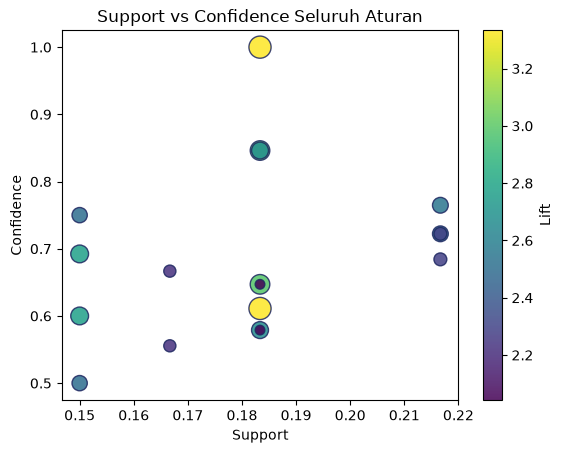

In [12]:
import matplotlib.pyplot as plt
sizes = (rules['lift'] - rules['lift'].min() + 0.3) * 160
sc = plt.scatter(rules['support'], rules['confidence'], s=sizes,
 c=rules['lift'], cmap='viridis', alpha=0.85, edgecolor='#1E2761')
plt.colorbar(sc, label='Lift')
plt.xlabel('Support'); plt.ylabel('Confidence')
plt.title('Support vs Confidence Seluruh Aturan')
plt.show()

## 4.6 Interpretasi Bisnis dari Aturan Terpilih

Tiga aturan dengan Lift tertinggi dari kelompok item berbeda:

1. **Mentega, Susu → Roti** (Lift 3.333, Confidence 100%)
   Kelompok "paket sarapan". Semua transaksi yang memuat Mentega dan Susu juga
   memuat Roti. Rekomendasi: letakkan ketiganya berdekatan atau buat bundling
   "Paket Sarapan Hemat" untuk menaikkan nilai belanja rata-rata.

2. **Sabun → Shampo** (Lift 2.769, Confidence 60%)
   Kelompok produk mandi. Rekomendasi: susun rak berdekatan (planogram) di area
   toiletries, terpisah dari rak sembako.

3. **Kecap → Mie Instan** (Lift 2.500, Confidence 75%)
   Pembeli Kecap berpeluang besar juga membeli Mie Instan. Rekomendasi: jadikan
   dasar fitur rekomendasi "pelanggan yang membeli ini juga membeli...".

Catatan: aturan asosiasi menunjukkan korelasi, bukan sebab-akibat, sehingga
keputusan bisnis perlu divalidasi lebih lanjut (misalnya dengan A/B testing).

## 4.7 Eksperimen: Pengaruh Nilai min_support

In [15]:
sweep_sup = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]
for s in sweep_sup:
 fi = apriori(df, min_support=s, use_colnames=True)
 r = (association_rules(fi, metric='confidence', min_threshold=0.5) 
    if len(fi) else pd.DataFrame())
 print(f'min_support={s:.2f}: {len(fi):2d} itemset, {len(r):2d} aturan')

min_support=0.10: 19 itemset, 20 aturan
min_support=0.15: 17 itemset, 18 aturan
min_support=0.20: 12 itemset,  4 aturan
min_support=0.25:  6 itemset,  0 aturan
min_support=0.30:  3 itemset,  0 aturan
min_support=0.35:  0 itemset,  0 aturan
min_support=0.40:  0 itemset,  0 aturan


min_support=0.10: 19 itemset, 20 aturan
min_support=0.15: 17 itemset, 18 aturan
min_support=0.20: 12 itemset,  4 aturan
min_support=0.25:  6 itemset,  0 aturan
min_support=0.30:  3 itemset,  0 aturan
min_support=0.35:  0 itemset,  0 aturan
min_support=0.40:  0 itemset,  0 aturan


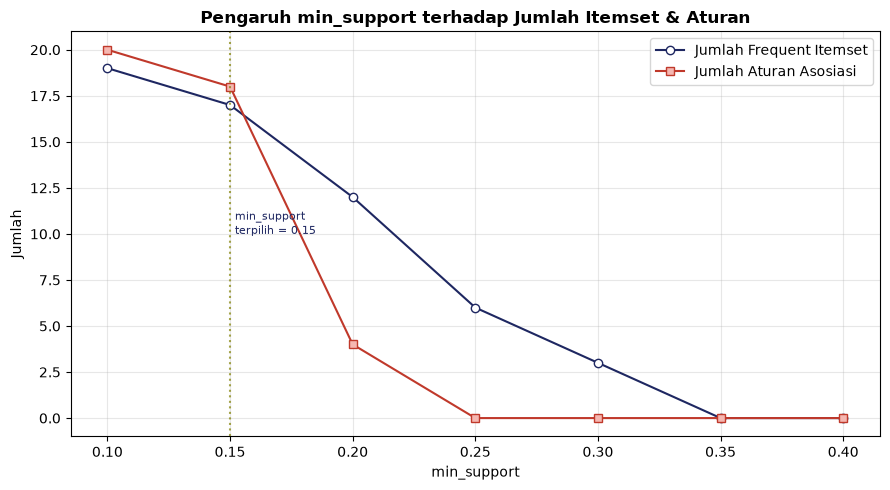

In [17]:
import matplotlib.pyplot as plt

sweep_sup = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]
n_itemset, n_aturan = [], []

for s in sweep_sup:
    fi = apriori(df, min_support=s, use_colnames=True)
    r = (association_rules(fi, metric='confidence', min_threshold=0.5)
         if len(fi) else pd.DataFrame())
    n_itemset.append(len(fi))
    n_aturan.append(len(r))
    print(f'min_support={s:.2f}: {len(fi):2d} itemset, {len(r):2d} aturan')

# Grafik
plt.figure(figsize=(9, 5))
plt.plot(sweep_sup, n_itemset, 'o-', color='#1E2761',
         markerfacecolor='white', label='Jumlah Frequent Itemset')
plt.plot(sweep_sup, n_aturan, 's-', color='#C0392B',
         markerfacecolor='#F5B7B1', label='Jumlah Aturan Asosiasi')

# Garis penanda min_support terpilih
plt.axvline(0.15, color='olive', linestyle=':', alpha=0.7)
plt.text(0.152, 10, 'min_support\nterpilih = 0.15', fontsize=8, color='#1E2761')

plt.title('Pengaruh min_support terhadap Jumlah Itemset & Aturan', fontweight='bold')
plt.xlabel('min_support')
plt.ylabel('Jumlah')
plt.xticks(sweep_sup)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 4.8 Eksperimen: Apriori vs FP-Growth

In [18]:
import time
t0 = time.perf_counter()
freq_apriori = apriori(df, min_support=0.15, use_colnames=True)
t_apriori = time.perf_counter() - t0
t0 = time.perf_counter()
freq_fpgrowth = fpgrowth(df, min_support=0.15, use_colnames=True)
t_fpgrowth = time.perf_counter() - t0
set_apriori = set(frozenset(s) for s in freq_apriori['itemsets'])
set_fpgrowth = set(frozenset(s) for s in freq_fpgrowth['itemsets'])
print(f'Apriori : {len(freq_apriori)} itemset, {t_apriori*1000:.2f} ms')
print(f'FP-Growth: {len(freq_fpgrowth)} itemset, {t_fpgrowth*1000:.2f} ms')
print('Itemset identik?', set_apriori == set_fpgrowth)

Apriori : 17 itemset, 2.76 ms
FP-Growth: 17 itemset, 1.39 ms
Itemset identik? True


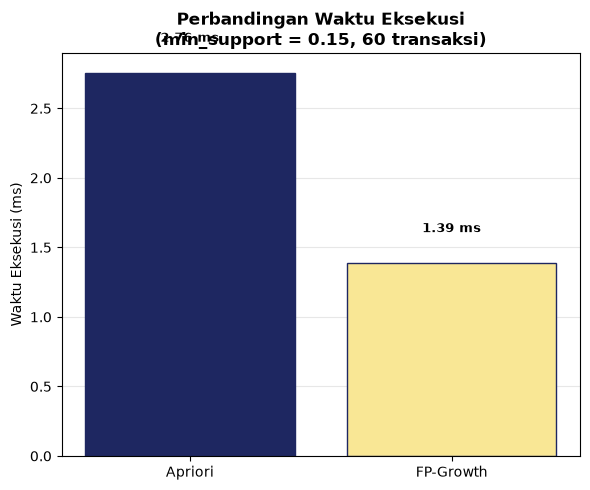

In [19]:
import matplotlib.pyplot as plt

algo  = ['Apriori', 'FP-Growth']
waktu = [t_apriori * 1000, t_fpgrowth * 1000]   # dalam ms

plt.figure(figsize=(6, 5))
bars = plt.bar(algo, waktu, color=['#1E2761', '#F9E795'], edgecolor='#1E2761')

# Tampilkan nilai di atas tiap bar
for bar, w in zip(bars, waktu):
    plt.text(bar.get_x() + bar.get_width()/2, w + 0.2, f'{w:.2f} ms',
             ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.title('Perbandingan Waktu Eksekusi\n(min_support = 0.15, 60 transaksi)',
          fontweight='bold')
plt.ylabel('Waktu Eksekusi (ms)')
plt.grid(axis='y', alpha=0.3)
plt.gca().set_axisbelow(True)
plt.tight_layout()
plt.show()